# Credit Risk Modelling & Credit Scorecard

**An end-to-end machine learning project using Lending Club loan data**

## Project overview
This project builds a binary classification model to estimate the probability that a borrower will default on a loan. The predicted probability is then translated into an illustrative credit score and a risk category.

## Business problem
Lenders need to assess the likelihood of repayment before approving a loan. A credit-risk model can support this assessment by estimating the probability of default (PD) from information available at application time.

## Objectives
- Prepare and explore historical Lending Club loan data.
- Define a binary loan-default target.
- Train and evaluate a Logistic Regression model.
- Convert model output into an illustrative 300–850 credit score.
- Group applicants into risk tiers and demonstrate scoring.

> **Important:** This is an educational portfolio project, not a production credit-underwriting system. The score scale and risk cut-offs are illustrative and would require validation, governance, fairness testing and business approval before real-world use.

## 1. Import libraries

Import the packages used for data manipulation, visualisation, preprocessing, model training, evaluation and saving the trained model.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss,
    confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Load the dataset

Place `accepted_2007_to_2018Q4.csv.gz` in the same folder as this notebook before running this section.

To keep the notebook manageable, the initial version reads the first 20,000 rows and then samples up to 10,000 resolved loans. This is a computational shortcut, not a representative sampling design for a production model.

In [2]:
DATA_PATH = "accepted_2007_to_2018Q4.csv.gz"

df = pd.read_csv(DATA_PATH, nrows=20_000, low_memory=False)

print(f"Raw data shape: {df.shape}")
display(df.head())

Raw data shape: (20000, 151)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,...,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,leadman,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,30.0,NaN,7.0,0.0,2765.0,29.7,13.0,w,0.00,0.00,4421.723917,4421.72,3600.00,821.72,0.0,0.0,0.0,Jan-2019,122.67,NaN,...,4.0,7.0,0.0,0.0,0.0,3.0,76.9,0.0,0.0,0.0,178050.0,7746.0,2400.0,13734.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,6.0,NaN,22.0,0.0,21470.0,19.2,38.0,w,0.00,0.00,25679.660000,25679.66,24700.00,979.66,0.0,0.0,0.0,Jun-2016,926.35,NaN,...,5.0,22.0,0.0,0.0,0.0,2.0,97.4,7.7,0.0,0.0,314017.0,39475.0,79300.0,24667.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,truck driver,10+ years,MORTGAGE,63000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,home_improvement,NaN,605xx,IL,10.78,0.0,Aug-2000,695.0,699.0,0.0,NaN,NaN,6.0,0.0,7869.0,56.2,18.0,w,0.00,0.00,22705.924294,22705.92,20000.00,2705.92,0.0,0.0,0.0,Jun-2017,15813.30,NaN,...,3.0,6.0,0.0,0.0,0.0,0.0,100.0,50.0,0.0,0.0,218418.0,18696.0,6200.0,14877.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,Information Systems Officer,10+ years,MORTGAGE,110000.0,Source Verified,Dec-2015,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,076xx,NJ,17.06,0.0,Sep-2008,785.0,789.0,0.0,NaN,NaN,13.0,0.0,7802.0,11.6,17.0,w,15897.65,15897.65,31464.010000,31464.01,19102.35,12361.66,0.0,0.0,0.0,Feb-2019,829.90,Apr-2019,...,5.0,13.0,0.0,0.0,0.0,1.0,100.0,0.0,0.0,0.0,381215.0,52226.0,62500.0,18000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 3. Select resolved loan records

For supervised learning, the outcome must be known. Keep loans with a final outcome of **Fully Paid**, **Charged Off** or **Default** (including the corresponding credit-policy status labels).

Sample up to 10,000 records reproducibly so the result does not depend on the order of the source rows.

In [3]:
valid_statuses = [
    "Fully Paid",
    "Charged Off",
    "Default",
    "Does not meet the credit policy. Status:Fully Paid",
    "Does not meet the credit policy. Status:Charged Off",
]

df = df[df["loan_status"].isin(valid_statuses)].copy()

sample_size = min(10_000, len(df))
df = df.sample(n=sample_size, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"Selected dataset shape: {df.shape}")
display(df["loan_status"].value_counts().to_frame("Loan count"))

Selected dataset shape: (10000, 151)


,Loan count
loan_status,
Fully Paid,7936
Charged Off,2064


## 4. Understand the dataset

Review the number of records and columns, data types and a sample of the available fields before making changes.

In [4]:
print("Dataset dimensions:", df.shape)
display(df.dtypes.value_counts().rename_axis("Data type").to_frame("Column count"))
display(df.head(5))

Dataset dimensions: (10000, 151)


,Column count
Data type,
float64,114
object,36
int64,1


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,...,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,67236068,NaN,10000.0,10000.0,10000.0,60 months,13.18,228.46,C,C3,Teacher,10+ years,MORTGAGE,64000.0,Source Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,891xx,NV,28.18,1.0,Nov-1998,750.0,754.0,0.0,15.0,NaN,9.0,0.0,324.0,1.5,23.0,w,0.0,0.0,11833.812341,11833.81,10000.00,1833.81,0.0,0.00,0.0000,Jun-2017,7957.31,NaN,...,1.0,9.0,0.0,0.0,0.0,2.0,87.0,0.0,0.0,0.0,182735.0,73826.0,15000.0,74532.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68366301,NaN,25000.0,25000.0,25000.0,36 months,6.49,766.12,A,A2,NaN,NaN,MORTGAGE,80000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,344xx,FL,17.11,0.0,Feb-1997,705.0,709.0,0.0,NaN,NaN,8.0,0.0,29315.0,73.7,26.0,w,0.0,0.0,27579.980448,27579.98,25000.00,2579.98,0.0,0.00,0.0000,Jan-2019,765.78,NaN,...,5.0,8.0,0.0,0.0,0.0,1.0,100.0,50.0,0.0,0.0,232488.0,41622.0,35800.0,20688.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68242916,NaN,8000.0,8000.0,8000.0,36 months,8.49,252.51,B,B1,Floor Attendant,5 years,RENT,80000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,863xx,AZ,17.58,0.0,Feb-1997,705.0,709.0,0.0,NaN,NaN,11.0,0.0,11660.0,61.0,15.0,w,0.0,0.0,8838.141856,8838.14,8000.00,838.14,0.0,0.00,0.0000,Sep-2017,1538.56,NaN,...,7.0,11.0,0.0,0.0,0.0,1.0,100.0,83.3,0.0,0.0,50235.0,30954.0,15800.0,31135.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,67458837,NaN,16000.0,16000.0,16000.0,60 months,16.55,393.79,D,D2,machine operator,6 years,OWN,50000.0,Not Verified,Dec-2015,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,major_purchase,Major purchase,273xx,NC,33.94,0.0,Oct-2009,675.0,679.0,0.0,NaN,NaN,11.0,0.0,11880.0,69.1,11.0,w,0.0,0.0,10643.600000,10643.60,4648.47,4393.99,0.0,1601.14,288.2052,Nov-2017,393.79,NaN,...,6.0,11.0,0.0,0.0,0.0,2.0,100.0,83.3,0.0,0.0,53052.0,35007.0,12700.0,35852.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 5. Define the target variable

Create `loan_status_flag`:
- `1` = default / charged off
- `0` = fully paid

The original outcome column is removed after creating the target so it cannot be used as a predictor.

In [5]:
default_statuses = {
    "Charged Off",
    "Default",
    "Does not meet the credit policy. Status:Charged Off",
}

df["loan_status_flag"] = df["loan_status"].isin(default_statuses).astype(int)
df = df.drop(columns=["loan_status"])

display(
    df["loan_status_flag"]
      .value_counts()
      .rename(index={0: "Non-default (0)", 1: "Default (1)"})
      .to_frame("Count")
)

,Count
loan_status_flag,
Non-default (0),7936
Default (1),2064


## 6. Remove leakage and unsuitable columns

Remove fields that are only known after loan issuance or repayment, as well as identifiers, free text and fields excluded from this analysis.

The list is based on the original notebook. The remaining predictors should still be reviewed carefully for the exact intended prediction timestamp before any real-world use.

In [6]:
leakage_cols = [
    "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee", "last_pymnt_d",
    "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_low", "last_fico_range_high", "pymnt_plan",
    "debt_settlement_flag", "debt_settlement_flag_date",
    "settlement_status", "settlement_date", "settlement_amount",
    "settlement_percentage", "settlement_term", "hardship_flag",
]

irrelevant_cols = [
    "id", "member_id", "url", "desc", "title", "zip_code",
    "addr_state", "policy_code", "funded_amnt", "funded_amnt_inv",
    "grade", "issue_d", "earliest_cr_line", "emp_title",
]

df = df.drop(columns=leakage_cols + irrelevant_cols, errors="ignore")

# Drop columns with more than 50% missing values.
missing_pct = df.isna().mean() * 100
high_missing_cols = missing_pct[missing_pct > 50].index.tolist()
df = df.drop(columns=high_missing_cols)

print("Removed high-missing columns:", len(high_missing_cols))
print("Shape after column filtering:", df.shape)

Removed high-missing columns: 34
Shape after column filtering: (10000, 79)


## 7. Basic data quality checks

Check missing values, duplicate rows and the target distribution. At this stage, do not calculate imputation values or encoding categories using the full dataset; those transformations will be fitted on training data only.

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget counts:")
display(df["loan_status_flag"].value_counts().to_frame("Count"))

print("\nTarget share (%):")
display((df["loan_status_flag"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

missing_summary = (
    df.isna().sum()
      .sort_values(ascending=False)
      .head(20)
      .to_frame("Missing values")
)
display(missing_summary)

Duplicate rows: 0

Target counts:


,Count
loan_status_flag,
0,7936
1,2064



Target share (%):


,Percentage
loan_status_flag,
0,79.36
1,20.64


,Missing values
mths_since_last_delinq,4810
il_util,1451
mths_since_recent_inq,1014
emp_length,637
mths_since_rcnt_il,461
num_tl_120dpd_2m,406
mo_sin_old_il_acct,275
max_bal_bc,190
open_rv_24m,190
open_acc_6m,190


## 8. Exploratory data analysis — default distribution

Visualise the class balance. The target is not perfectly balanced, so stratified splitting is used later to preserve a similar default proportion in both subsets.

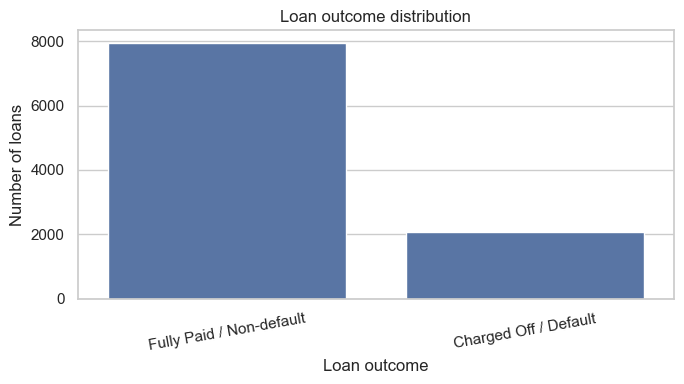

In [8]:
target_counts = df["loan_status_flag"].value_counts().sort_index()
target_labels = ["Fully Paid / Non-default", "Charged Off / Default"]

plt.figure(figsize=(7, 4))
sns.barplot(x=target_labels, y=[target_counts.get(0, 0), target_counts.get(1, 0)])
plt.title("Loan outcome distribution")
plt.xlabel("Loan outcome")
plt.ylabel("Number of loans")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 9. Exploratory data analysis — numerical features

Inspect selected numeric variables where available. These charts are descriptive and do not imply that a relationship is causal.

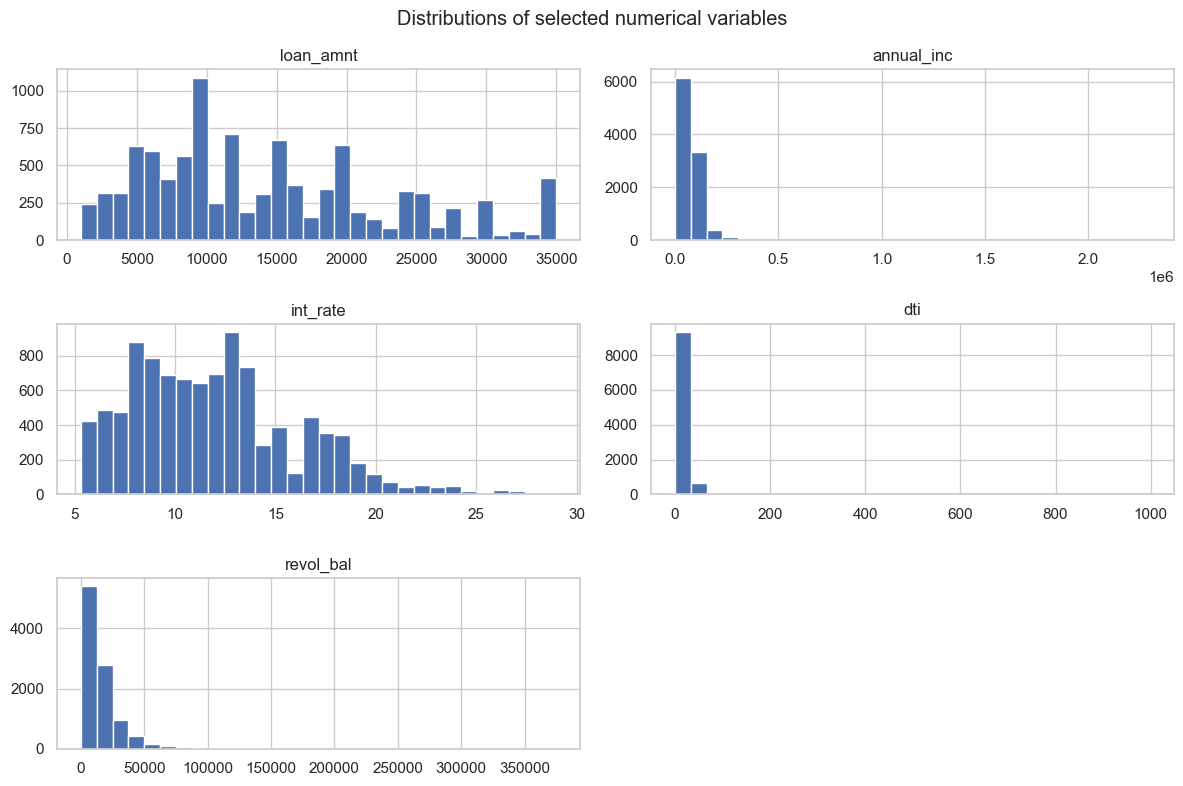

In [9]:
eda_numeric_candidates = ["loan_amnt", "annual_inc", "int_rate", "dti", "revol_bal"]
eda_numeric_cols = [c for c in eda_numeric_candidates if c in df.columns]

if eda_numeric_cols:
    df[eda_numeric_cols].hist(figsize=(12, 8), bins=30)
    plt.suptitle("Distributions of selected numerical variables")
    plt.tight_layout()
    plt.show()
else:
    print("No selected numerical EDA columns are available in this dataset extract.")

## 10. Exploratory data analysis — default rate by selected categories

Compare observed default rates across a few categorical fields. Categories with very small counts should be interpreted cautiously.

In [10]:
eda_category_candidates = ["term", "home_ownership", "verification_status", "purpose"]
eda_category_cols = [c for c in eda_category_candidates if c in df.columns]

for col in eda_category_cols:
    summary = (
        df.groupby(col, dropna=False)["loan_status_flag"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "default_rate"})
          .sort_values("default_rate", ascending=False)
          .head(12)
    )
    print(f"Default rate by {col}")
    display(summary.style.format({"default_rate": "{:.1%}"}))

Default rate by term


,count,default_rate
term,,
60 months,2163,37.5%
36 months,7837,16.0%


Default rate by home_ownership


,count,default_rate
home_ownership,,
RENT,4038,24.4%
OWN,1190,20.9%
MORTGAGE,4772,17.4%


Default rate by verification_status


,count,default_rate
verification_status,,
Verified,3022,25.6%
Source Verified,4001,20.5%
Not Verified,2977,15.8%


Default rate by purpose


,count,default_rate
purpose,,
small_business,105,28.6%
house,41,26.8%
major_purchase,208,24.5%
debt_consolidation,5590,22.7%
medical,125,22.4%
moving,56,21.4%
vacation,70,21.4%
car,96,19.8%
other,587,19.1%


## 11. Prepare deterministic feature transformations

Convert fields with a known, fixed interpretation:
- `term`: extract the number of months from strings such as `36 months`.
- `emp_length`: map employment-length labels to approximate years.

These mappings are rule-based rather than learned from the full dataset. Other missing-value handling and categorical encoding are deferred until after the train-test split.

In [11]:
if "term" in df.columns:
    df["term"] = pd.to_numeric(
        df["term"].astype("string").str.extract(r"(\d+)")[0],
        errors="coerce"
    )

if "emp_length" in df.columns:
    emp_map = {
        "< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3,
        "4 years": 4, "5 years": 5, "6 years": 6, "7 years": 7,
        "8 years": 8, "9 years": 9, "10+ years": 10,
    }
    df["emp_length"] = df["emp_length"].map(emp_map)

display(df.head())

,loan_amnt,term,int_rate,installment,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,collections_12_mths_ex_med,application_type,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_inq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,disbursement_method,loan_status_flag
0,10000.0,60,13.18,228.46,C3,10.0,MORTGAGE,64000.0,Source Verified,debt_consolidation,28.18,1.0,750.0,754.0,0.0,15.0,9.0,0.0,324.0,1.5,23.0,w,0.0,Individual,0.0,0.0,154928.0,1.0,3.0,2.0,2.0,5.0,73502.0,99.0,0.0,1.0,324.0,77.0,21300.0,0.0,1.0,1.0,3.0,17214.0,14676.0,2.2,0.0,0.0,169.0,205.0,23.0,5.0,2.0,23.0,2.0,0.0,1.0,1.0,3.0,4.0,9.0,5.0,12.0,1.0,9.0,0.0,0.0,0.0,2.0,87.0,0.0,0.0,0.0,182735.0,73826.0,15000.0,74532.0,Cash,0
1,25000.0,36,6.49,766.12,A2,NaN,MORTGAGE,80000.0,Not Verified,debt_consolidation,17.11,0.0,705.0,709.0,0.0,NaN,8.0,0.0,29315.0,73.7,26.0,w,0.0,Individual,0.0,0.0,210290.0,0.0,2.0,0.0,1.0,20.0,12307.0,60.0,1.0,1.0,9969.0,69.0,39800.0,1.0,0.0,1.0,3.0,26286.0,7745.0,78.4,0.0,0.0,86.0,226.0,7.0,7.0,1.0,32.0,7.0,0.0,4.0,5.0,4.0,16.0,4.0,5.0,21.0,5.0,8.0,0.0,0.0,0.0,1.0,100.0,50.0,0.0,0.0,232488.0,41622.0,35800.0,20688.0,Cash,0
2,8000.0,36,8.49,252.51,B1,5.0,RENT,80000.0,Not Verified,debt_consolidation,17.58,0.0,705.0,709.0,0.0,NaN,11.0,0.0,11660.0,61.0,15.0,w,0.0,Individual,0.0,0.0,30954.0,1.0,3.0,0.0,2.0,13.0,19294.0,62.0,1.0,2.0,5124.0,62.0,19100.0,2.0,0.0,2.0,4.0,2814.0,4759.0,69.9,0.0,0.0,117.0,226.0,4.0,4.0,1.0,4.0,3.0,0.0,6.0,7.0,6.0,6.0,6.0,8.0,8.0,7.0,11.0,0.0,0.0,0.0,1.0,100.0,83.3,0.0,0.0,50235.0,30954.0,15800.0,31135.0,Cash,0
3,16000.0,60,16.55,393.79,D2,6.0,OWN,50000.0,Not Verified,major_purchase,33.94,0.0,675.0,679.0,0.0,NaN,11.0,0.0,11880.0,69.1,11.0,w,0.0,Individual,0.0,0.0,35007.0,1.0,3.0,1.0,2.0,4.0,23127.0,65.0,1.0,3.0,4933.0,66.0,17200.0,1.0,0.0,0.0,5.0,3182.0,820.0,93.5,0.0,0.0,45.0,74.0,11.0,4.0,0.0,11.0,15.0,0.0,6.0,6.0,6.0,6.0,3.0,8.0,8.0,6.0,11.0,0.0,0.0,0.0,2.0,100.0,83.3,0.0,0.0,53052.0,35007.0,12700.0,35852.0,Cash,1
4,15000.0,36,13.99,512.60,C4,4.0,RENT,68000.0,Verified,debt_consolidation,28.29,0.0,665.0,669.0,0.0,NaN,7.0,0.0,7465.0,99.5,41.0,w,0.0,Individual,0.0,0.0,140216.0,2.0,5.0,3.0,7.0,2.0,132751.0,97.0,0.0,0.0,2437.0,97.0,7500.0,2.0,3.0,2.0,7.0,20031.0,63.0,97.5,0.0,0.0,123.0,136.0,29.0,2.0,0.0,117.0,9.0,0.0,1.0,2.0,1.0,3.0,36.0,2.0,5.0,2.0,7.0,0.0,0.0,0.0,3.0,100.0,100.0,0.0,0.0,138825.0,140216.0,2500.0,131325.0,Cash,0


## 12. Separate predictors and target

Separate `X` and `y` before splitting. The test set is held back until final evaluation.

In [12]:
X = df.drop(columns=["loan_status_flag"])
y = df["loan_status_flag"].astype(int)

print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)

Predictor matrix: (10000, 78)
Target vector: (10000,)


## 13. Train-test split

Use an 80/20 stratified split. Stratification maintains approximately the same default share in the training and test sets.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print(f"Training default rate: {y_train.mean():.2%}")
print(f"Test default rate    : {y_test.mean():.2%}")

X_train: (8000, 78)
X_test : (2000, 78)
Training default rate: 20.64%
Test default rate    : 20.65%


## 14. Identify numerical and categorical columns

Determine column types from the training data. The same column lists are then used to transform the test data consistently.

In [14]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 71
Categorical features: 7


## 15. Build the preprocessing pipeline

Numerical features:
- Fill missing values using the training-set median.
- Standardise using training-set means and standard deviations.

Categorical features:
- Fill missing values using the most frequent training value.
- One-hot encode categories.
- Ignore previously unseen categories in the test set.

Because the preprocessing is inside a Scikit-learn pipeline, the imputation, encoding and scaling steps are fitted only on training data. This prevents the test set from influencing preprocessing.

In [15]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

## 16. Train Logistic Regression

Combine preprocessing and Logistic Regression in one pipeline. Fit the complete pipeline using only the training data.

In [16]:
credit_risk_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

credit_risk_model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 17. Generate predictions on unseen test data

Use the fitted model to obtain predicted probabilities of default and class predictions for the held-out test set.

In [17]:
y_test_pd = credit_risk_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_pd >= 0.50).astype(int)

prediction_results = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Predicted_Default": y_test_pred,
    "Predicted_PD_%": (y_test_pd * 100).round(2),
})

display(prediction_results.head(10))

,Actual_Default,Predicted_Default,Predicted_PD_%
0,0,0,19.64
1,1,1,50.77
2,0,0,16.49
3,0,0,26.35
4,0,0,12.87
5,0,1,70.32
6,0,0,34.56
7,0,0,7.06
8,1,0,19.87
9,1,0,23.21


## 18. Evaluate model performance

Report ROC-AUC, Gini, Kolmogorov–Smirnov (KS) statistic and Brier score.

- **ROC-AUC:** ranking ability across thresholds.
- **Gini:** `2 × AUC − 1`.
- **KS:** maximum separation between cumulative default and non-default distributions.
- **Brier score:** mean squared error of predicted probabilities; lower is better.

The model is Logistic Regression, but its probabilities have not been separately calibrated. Therefore, these outputs should not be described as a calibrated model.

In [18]:
auc = roc_auc_score(y_test, y_test_pd)
gini = 2 * auc - 1
fpr, tpr, thresholds = roc_curve(y_test, y_test_pd)
ks_stat = float(np.max(tpr - fpr))
brier = brier_score_loss(y_test, y_test_pd)

print("Model performance on the held-out test set")
print(f"ROC-AUC  : {auc:.4f}")
print(f"Gini     : {gini:.4f}")
print(f"KS       : {ks_stat:.4f}")
print(f"Brier    : {brier:.4f}")
print(f"Mean predicted PD: {y_test_pd.mean():.2%}")
print(f"Observed default rate: {y_test.mean():.2%}")

Model performance on the held-out test set
ROC-AUC  : 0.7407
Gini     : 0.4814
KS       : 0.3604
Brier    : 0.1453
Mean predicted PD: 21.04%
Observed default rate: 20.65%


## 19. Classification report and confusion matrix

The default 0.50 probability threshold is used here only to provide a basic classification report. In credit risk, the operating threshold should be selected based on business costs, approval strategy and validation.

              precision    recall  f1-score   support

 Non-default       0.81      0.96      0.88      1587
     Default       0.52      0.15      0.24       413

    accuracy                           0.80      2000
   macro avg       0.67      0.56      0.56      2000
weighted avg       0.75      0.80      0.75      2000



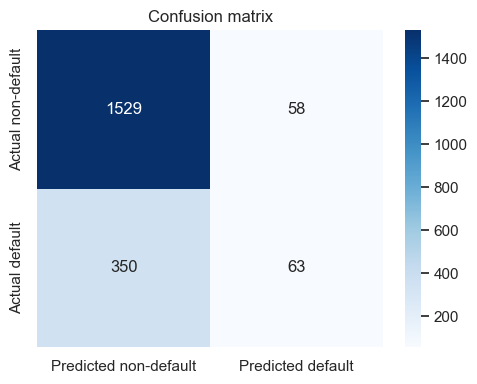

In [19]:
print(classification_report(
    y_test, y_test_pred,
    target_names=["Non-default", "Default"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted non-default", "Predicted default"],
    yticklabels=["Actual non-default", "Actual default"]
)
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

## 20. Convert probability of default into an illustrative credit score

Transform the model's log-odds into a score between 300 and 850.

Assumptions carried forward from the original project:
- Base score = 650 at 1:1 odds.
- Points to double the odds (PDO) = 40.
- Higher scores represent lower predicted default risk.

This is a project-specific score mapping, not an externally validated bureau score.

In [20]:
PDO = 40
BASE_SCORE = 650
pdo_factor = PDO / np.log(2)

log_odds_bad = credit_risk_model.decision_function(X_test)
log_odds_good = -log_odds_bad

credit_scores = np.clip(
    BASE_SCORE + pdo_factor * log_odds_good,
    300, 850
).round().astype(int)

results_df = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Predicted_PD_%": (y_test_pd * 100).round(2),
    "Credit_Score": credit_scores,
})

display(results_df.head(10))
print("\nAverage credit score by actual outcome:")
display(results_df.groupby("Actual_Default")["Credit_Score"].mean().round(1))

,Actual_Default,Predicted_PD_%,Credit_Score
0,0,19.64,731
1,1,50.77,648
2,0,16.49,744
3,0,26.35,709
4,0,12.87,760
5,0,70.32,600
6,0,34.56,687
7,0,7.06,799
8,1,19.87,730
9,1,23.21,719



Average credit score by actual outcome:


Actual_Default
0    752.5
1    702.0
Name: Credit_Score, dtype: float64

## 21. Assign applicants to risk tiers

Use the same illustrative score bands from the original notebook:
- Low Risk: 760+
- Medium Risk: 710–759
- High Risk: 660–709
- Very High Risk: below 660

In [21]:
def assign_risk_tier(score):
    if score >= 760:
        return "1. Low Risk (760+)"
    elif score >= 710:
        return "2. Medium Risk (710-759)"
    elif score >= 660:
        return "3. High Risk (660-709)"
    return "4. Very High Risk (<660)"

results_df["Risk_Tier"] = results_df["Credit_Score"].apply(assign_risk_tier)

tier_summary = (
    results_df.groupby("Risk_Tier", sort=True)
    .agg(
        Total_Borrowers=("Actual_Default", "count"),
        Actual_Defaults=("Actual_Default", "sum"),
        Actual_Default_Rate_Pct=("Actual_Default", lambda s: s.mean() * 100),
        Avg_Predicted_PD_Pct=("Predicted_PD_%", "mean"),
        Avg_Credit_Score=("Credit_Score", "mean"),
    )
)

display(tier_summary.round(2))

,Total_Borrowers,Actual_Defaults,Actual_Default_Rate_Pct,Avg_Predicted_PD_Pct,Avg_Credit_Score
Risk_Tier,,,,,
1. Low Risk (760+),767,57,7.43,7.04,803.76
2. Medium Risk (710-759),631,122,19.33,18.92,735.03
3. High Risk (660-709),423,145,34.28,34.75,686.90
4. Very High Risk (<660),179,89,49.72,56.11,632.79


## 22. Visualise model performance and risk drivers

The first chart shows the ROC curve. The second shows the largest absolute Logistic Regression coefficients after preprocessing. Coefficient magnitude is not a causal measure of feature importance.

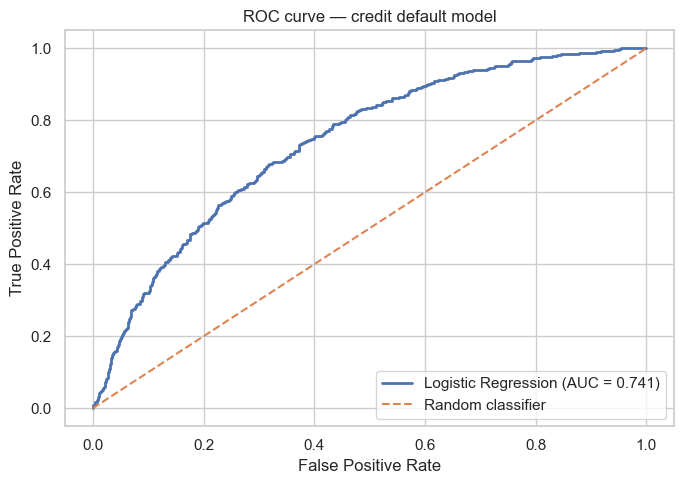

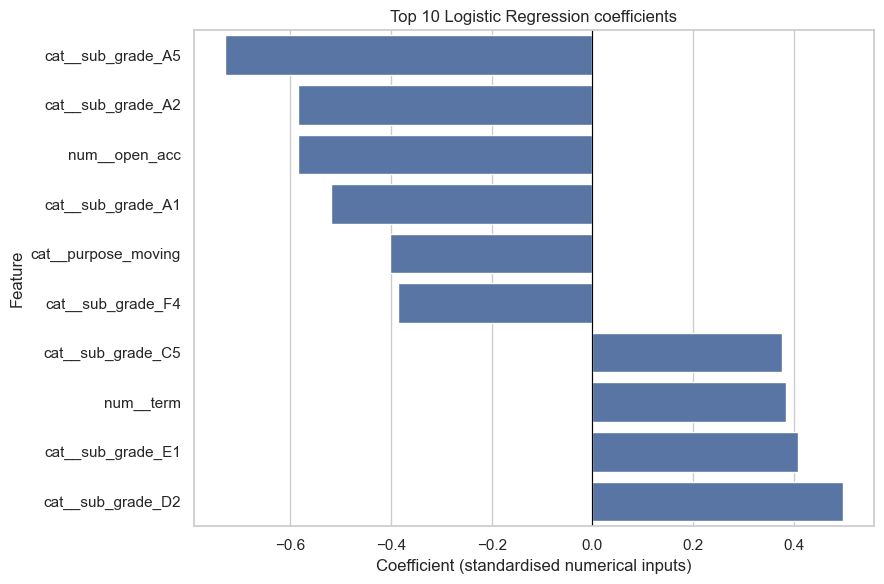

In [22]:
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve — credit default model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

feature_names = credit_risk_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = credit_risk_model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
})
coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

top_features = (
    coef_df.nlargest(10, "Absolute_Coefficient")
           .sort_values("Coefficient")
)

plt.figure(figsize=(9, 6))
sns.barplot(data=top_features, x="Coefficient", y="Feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 Logistic Regression coefficients")
plt.xlabel("Coefficient (standardised numerical inputs)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 23. Interpret the risk-tier results

Check whether observed default rates generally rise as the risk category becomes riskier. Small groups and sampling variation can affect this pattern; monotonicity should be validated on larger, representative data before operational use.

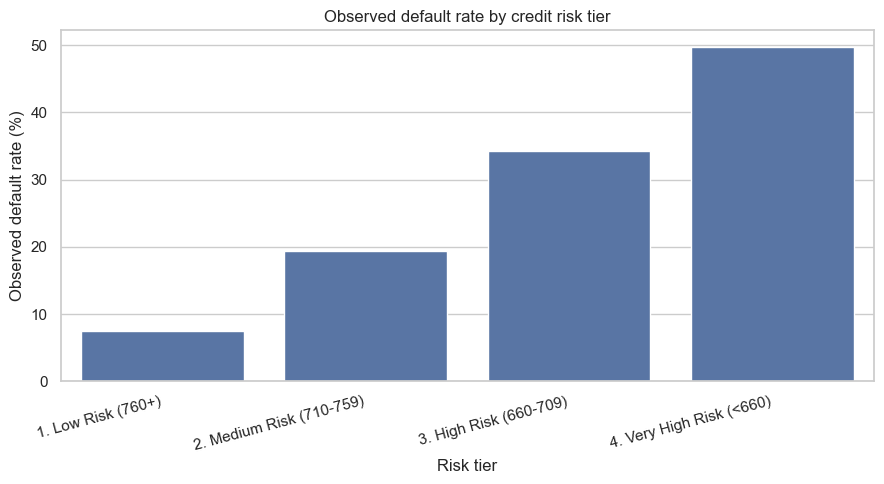

In [23]:
tier_plot = tier_summary.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=tier_plot,
    x="Risk_Tier",
    y="Actual_Default_Rate_Pct"
)
plt.title("Observed default rate by credit risk tier")
plt.xlabel("Risk tier")
plt.ylabel("Observed default rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 24. Save the complete model pipeline

Save the complete preprocessing-plus-model pipeline so the same transformations are applied when scoring future records. Also save the input column names and scorecard assumptions.

In [24]:
model_artifacts = {
    "pipeline": credit_risk_model,
    "input_features": X_train.columns.tolist(),
    "base_score": BASE_SCORE,
    "pdo": PDO,
    "risk_tier_function_note": "See assign_risk_tier() in this notebook.",
}

MODEL_PATH = "credit_risk_scorecard.pkl"
joblib.dump(model_artifacts, MODEL_PATH)

print(f"Saved model artifacts to: {MODEL_PATH}")

Saved model artifacts to: credit_risk_scorecard.pkl


## 25. Demonstrate scoring a new applicant record

For demonstration, take one held-out test record and score it through the saved pipeline. This simulates the scoring flow while keeping the preprocessing steps consistent.

For a real applicant, provide a record with the same raw input columns and apply the same deterministic feature transformations used above.

In [25]:
sample_applicant = X_test.iloc[[0]].copy()

sample_pd = credit_risk_model.predict_proba(sample_applicant)[0, 1]
sample_log_odds_good = -credit_risk_model.decision_function(sample_applicant)[0]

sample_score = int(np.clip(
    BASE_SCORE + pdo_factor * sample_log_odds_good,
    300, 850
).round())

sample_tier = assign_risk_tier(sample_score)

print("Single applicant scoring demonstration")
print(f"Predicted Probability of Default: {sample_pd:.2%}")
print(f"Illustrative Credit Score       : {sample_score}")
print(f"Assigned Risk Tier              : {sample_tier}")

Single applicant scoring demonstration
Predicted Probability of Default: 19.64%
Illustrative Credit Score       : 731
Assigned Risk Tier              : 2. Medium Risk (710-759)


## 26. Conclusion

This project demonstrates an end-to-end credit-risk modelling workflow using historical Lending Club loan records. It includes data selection, target construction, exploratory analysis, leakage-aware preprocessing, Logistic Regression, model evaluation, an illustrative credit scorecard and risk-tier analysis.

### Key outputs
- Probability of Default (PD) for each test-set borrower.
- ROC-AUC, Gini, KS and Brier score evaluation metrics.
- An illustrative 300–850 credit score.
- Four credit risk tiers and their observed default rates.
- A reusable Scikit-learn pipeline saved as `credit_risk_scorecard.pkl`.

### Limitations and future improvements
- Use the complete dataset and a time-based validation strategy.
- Review every predictor for availability at the actual loan decision timestamp.
- Perform calibration analysis and, if appropriate, probability calibration.
- Assess fairness, stability, drift, explainability and regulatory requirements.
- Tune risk cut-offs using business costs and lending policy.
- Validate the scorecard on an independent, representative out-of-time sample.

**Disclaimer:** The model and scorecard are for learning and demonstration only. They should not be used to make real lending decisions.